### Data 620 - Week Eight Assignment
####Text Mining: High-Frequency Words and Word Association

Please answer the following questions in an IPython Notebook, posted to GitHub.
1. Choose a corpus of interest.
2. How many total unique words are in the corpus? (Please feel free to define unique words in any interesting, defensible way).
3. Taking the most common words, how many unique words represent half of the total words in the corpus?
4. Identify the 200 highest frequency words in this corpus.
5. Create a graph that shows the relative frequency of these 200 words.
6. Does the observed relative frequency of these words follow Zipf’s law? Explain.
7. In what ways do you think the frequency of the words in this corpus differ from “all words in all corpora.”

#### Introduction

This assignment analyzes word frequency in a corpus of public health articles published by the World Health Organization (WHO). The articles focus on disease prevention, vaccines, cancer, and public health.

The objectives are to measure the vocabulary size of the corpus, identify the most frequent words, visualize their relative frequencies, evaluate whether the distribution follows Zipf's law, and consider how public health writing differs from language in a general corpus.

The corpus consists of five online articles. Words are converted to lowercase, and punctuation and numbers are excluded from the primary analysis. Stopwords are retained because common grammatical words are important when examining the overall word-frequency distribution and Zipf's law. A unique word is defined as a distinct lowercase alphabetic token.

#### Install and import the tools

Here I install and import the necessary libraries for this project.

In [1]:
#!pip install requests beautifulsoup4 pandas matplotlib nltk wordcloud

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import nltk
import time

from bs4 import BeautifulSoup
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from nltk import FreqDist
from nltk.tokenize import RegexpTokenizer
from wordcloud import WordCloud

pd.set_option("display.max_colwidth", 100)

#### Corpus Selection and Article Manifest

This code selects five WHO articles about vaccines and cancer prevention to create a public health corpus. It stores each article’s source, title, and URL in a list, then converts the list into a pandas DataFrame called article_manifest for easy organization and access.

The DataFrame displays five rows and three columns (source, title, and url), listing all five articles. It lists each WHO article, its title, and its web link, organizing the corpus for analysis. The table provides the foundation for examining word frequencies, but the article text still needs to be collected and processed.

In [2]:
# Select the corpus: Public Health Data

articles = [
    {
        "source": "WHO",
        "title": "How Do Vaccines Work?",
        "url": "https://www.who.int/news-room/feature-stories/detail/how-do-vaccines-work"
    },
    {
        "source": "WHO",
        "title": "Vaccine Efficacy, Effectiveness and Protection",
        "url": "https://www.who.int/news-room/feature-stories/detail/vaccine-efficacy-effectiveness-and-protection"
    },
    {
        "source": "WHO",
        "title": "Ensuring Vaccine Safety",
        "url": "https://www.who.int/news-room/feature-stories/detail/safety-of-covid-19-vaccines"
    },
    {
        "source": "WHO",
        "title": "Counting the Impact of Vaccines",
        "url": "https://www.who.int/news-room/feature-stories/detail/counting-the-impact-of-vaccines"
    },
    {
        "source": "WHO",
        "title": "Four in Ten Cancer Cases Could Be Prevented Globally",
        "url": "https://www.who.int/news/item/03-02-2026-four-in-ten-cancer-cases-could-be-prevented-globally"
    }
]

article_manifest = pd.DataFrame(articles)
article_manifest[["source", "title", "url"]]

,source,title,url
0,WHO,How Do Vaccines Work?,https://www.who.int/news-room/feature-stories/detail/how-do-vaccines-work
1,WHO,"Vaccine Efficacy, Effectiveness and Protection",https://www.who.int/news-room/feature-stories/detail/vaccine-efficacy-effectiveness-and-protection
2,WHO,Ensuring Vaccine Safety,https://www.who.int/news-room/feature-stories/detail/safety-of-covid-19-vaccines
3,WHO,Counting the Impact of Vaccines,https://www.who.int/news-room/feature-stories/detail/counting-the-impact-of-vaccines
4,WHO,Four in Ten Cancer Cases Could Be Prevented Globally,https://www.who.int/news/item/03-02-2026-four-in-ten-cancer-cases-could-be-prevented-globally


#### Downloading and Extracting Article Text

This code downloads the five WHO articles, extracts their main text, and stores the results in a dataframe. It includes retry attempts for failed requests, removes unnecessary webpage elements, and calculates the raw word count for each article. This step collects the actual text needed to analyze word frequencies, identify unique words, and test Zipf’s law. All five articles downloaded successfully, with zero failed downloads. Their raw word counts are 1,167, 560, 876, 608, and 617, respectively. The results confirm that the corpus is ready for further word-frequency analysis.

In [3]:
# Download and extract article title

session = requests.Session()

retry_strategy = Retry(
    total=3,
    backoff_factor=1,
    status_forcelist=[429, 500, 502, 503, 504],
    allowed_methods=["GET"]
)

session.mount("https://", HTTPAdapter(max_retries=retry_strategy))

def extract_article_text(url):
    headers = {
        "User-Agent": "Mozilla/5.0 (compatible; AcademicResearch/1.0)",
        "Accept-Language": "en-US,en;q=0.9"
    }

    try:
        response = session.get(
            url,
            headers=headers,
            timeout=30
        )
        response.raise_for_status()

        soup = BeautifulSoup(response.text, "html.parser")

        for element in soup([
            "script", "style", "nav", "footer",
            "header", "aside", "noscript", "form"
        ]):
            element.decompose()

        main = soup.find("main") or soup.find("article") or soup.body

        if main is None:
            return ""

        elements = main.find_all(["p", "h1", "h2", "h3"])

        return " ".join(
            element.get_text(" ", strip=True)
            for element in elements
        )

    except requests.RequestException as error:
        print(f"Download failed: {url}")
        print(error)
        return ""

article_texts = []

for article in articles:
    print("Downloading:", article["title"])

    text = extract_article_text(article["url"])

    article_texts.append({
        "source": article["source"],
        "title": article["title"],
        "url": article["url"],
        "text": text
    })

    time.sleep(1)

corpus_df = pd.DataFrame(article_texts)
corpus_df["text"] = corpus_df["text"].fillna("")

# Exclude documents with failed or empty downloads
corpus_df = corpus_df[
    corpus_df["text"].str.strip().ne("")
].copy().reset_index(drop=True)

corpus_df["word_count_raw"] = (
    corpus_df["text"].str.split().str.len()
)

print("\nSuccessfully retrieved articles:", len(corpus_df))
print("Failed/empty articles:", len(articles) - len(corpus_df))

display(corpus_df[["source", "title", "word_count_raw"]])

if corpus_df.empty:
    raise ValueError(
        "No articles downloaded successfully. "
    )



Downloading: How Do Vaccines Work?
Downloading: Vaccine Efficacy, Effectiveness and Protection
Downloading: Ensuring Vaccine Safety
Downloading: Counting the Impact of Vaccines
Downloading: Four in Ten Cancer Cases Could Be Prevented Globally

Successfully retrieved articles: 5
Failed/empty articles: 0


,source,title,word_count_raw
0,WHO,How Do Vaccines Work?,1167
1,WHO,"Vaccine Efficacy, Effectiveness and Protection",560
2,WHO,Ensuring Vaccine Safety,876
3,WHO,Counting the Impact of Vaccines,608
4,WHO,Four in Ten Cancer Cases Could Be Prevented Globally,617


#### Tokenization and Word Normalization

This code breaks the article text into individual words, converts them to lowercase, and removes punctuation and numbers. It retains common words (stopwords) and uses `FreqDist` to count how often each word appears. It then calculates the total word occurrences (`total_tokens`) and the number of unique words (`unique_types`). Standardizing the words ensures consistent counting across all five articles and provides the data needed to analyze vocabulary size and word frequencies.

In [4]:
# Tokenization and word normalization

# Definition: alphabetic sequences, converted to lowercase.
# Punctuation and numbers are excluded; stopwords are retained.

tokenizer = RegexpTokenizer(r"[A-Za-z]+")

tokens = []

for text in corpus_df["text"]:
    tokens.extend(
        word.lower()
        for word in tokenizer.tokenize(text)
    )

if not tokens:
    raise ValueError("The downloaded articles contained no usable word tokens.")

fdist = FreqDist(tokens)

total_tokens = len(tokens)
unique_types = len(set(tokens))

#### Total Unique Words in the Corpus

This code prints the total number of word occurrences, the number of unique words, and the type-token ratio. These measurements show the size and diversity of the corpus's vocabulary.

The corpus contains 3,790 total word tokens and 1,034 unique word types. The type-token ratio is 0.2728 (27.28%), meaning there are approximately 27 unique words for every 100 word occurrences.

In [5]:
# 2. How many total unique words are in the corpus? (Please feel free to define unique words in any interesting,defensible way).

print(f"Total word tokens: {total_tokens:,}")
print(f"Total unique word types: {unique_types:,}")
print(f"Type-token ratio: {unique_types / total_tokens:.4f}")

Total word tokens: 3,790
Total unique word types: 1,034
Type-token ratio: 0.2728


#### Most Common Words Accounting for Half the Corpus

This code ranks words by frequency and calculates their cumulative frequency until they account for at least 50% of all word occurrences. This identifies how concentrated the vocabulary is and whether a relatively small number of common words dominate the corpus.

The 77 most frequent unique words account for 50.05% of all 3,790 word occurrences. This indicates that a relatively small portion of the vocabulary makes up half of the words used in the five articles.

In [6]:
# 3. Taking the most common words, how many unique words represent half of the total words in the corpus?

frequency_table = pd.DataFrame(
    fdist.most_common(),
    columns=["word", "count"]
)

frequency_table["relative_frequency"] = (
    frequency_table["count"] / total_tokens
)

frequency_table["cumulative_count"] = (
    frequency_table["count"].cumsum()
)

frequency_table["cumulative_frequency"] = (
    frequency_table["cumulative_count"] / total_tokens
)

frequency_table["relative_frequency_percent"] = (
    frequency_table["relative_frequency"] * 100
)


half_index = frequency_table[
    frequency_table["cumulative_frequency"] >= 0.50
].index[0]

words_for_half = half_index + 1
half_coverage = frequency_table.loc[
    half_index, "cumulative_frequency"
]

print(
    f"The {words_for_half} most frequent unique word types "
    f"account for {half_coverage:.2%} of all word tokens."
)


The 77 most frequent unique word types account for 50.05% of all word tokens.


#### Identifying the 200 Most Frequent Words

This code selects the 200 most frequently occurring words, ranks them from 1 to 200, and displays their counts and relative frequencies. It also saves the top 200 words and the complete frequency table as CSV files. This identifies the most common vocabulary in the corpus and provides data for graphing and analyzing word-frequency patterns.

The table contains 200 ranked words. “The” is the most frequent, appearing 178 times (4.70%), followed by “and” with 155 occurrences (4.09%). The 200th-ranked word, “infected,” appears four times. Together, these 200 words account for approximately 67.70% of all word tokens, showing that frequently used words make up a substantial portion of the corpus.

In [7]:
# Identify the 200 highest frequency words in this corpus

top_200 = frequency_table.head(200).copy()

top_200.index = range(1, len(top_200) + 1)
top_200.index.name = "rank"

display(top_200)

# Save results to CSV files
top_200.to_csv("top_200_words.csv")
frequency_table.to_csv("complete_word_frequencies.csv", index=False)

,word,count,relative_frequency,cumulative_count,cumulative_frequency,relative_frequency_percent
rank,,,,,,
1,the,178,0.046966,178,0.046966,4.696570
2,and,155,0.040897,333,0.087863,4.089710
3,to,115,0.030343,448,0.118206,3.034301
4,of,92,0.024274,540,0.142480,2.427441
5,in,81,0.021372,621,0.163852,2.137203
...,...,...,...,...,...,...
196,include,4,0.001055,2550,0.672823,0.105541
197,age,4,0.001055,2554,0.673879,0.105541
198,three,4,0.001055,2558,0.674934,0.105541


#### Word Cloud of WHO Public Health Articles

What: The code creates a word cloud using the word frequencies from the five WHO articles. More frequent words appear larger, making the most prominent topics easy to identify. This visualization helps identify the main themes and recurring vocabulary in the public health corpus.

The word cloud highlights terms such as “vaccine,” “vaccines,” “health,” “vaccinated,” and “diseases,” suggesting a strong focus on vaccination and disease prevention. Other words, including “safety,” “effective,” “protection,” “children,” and “people,” reflect attention to vaccine effectiveness and public health protection. Overall, the word cloud illustrates the emphasis these articles place on vaccination and its role in protecting health worldwide.

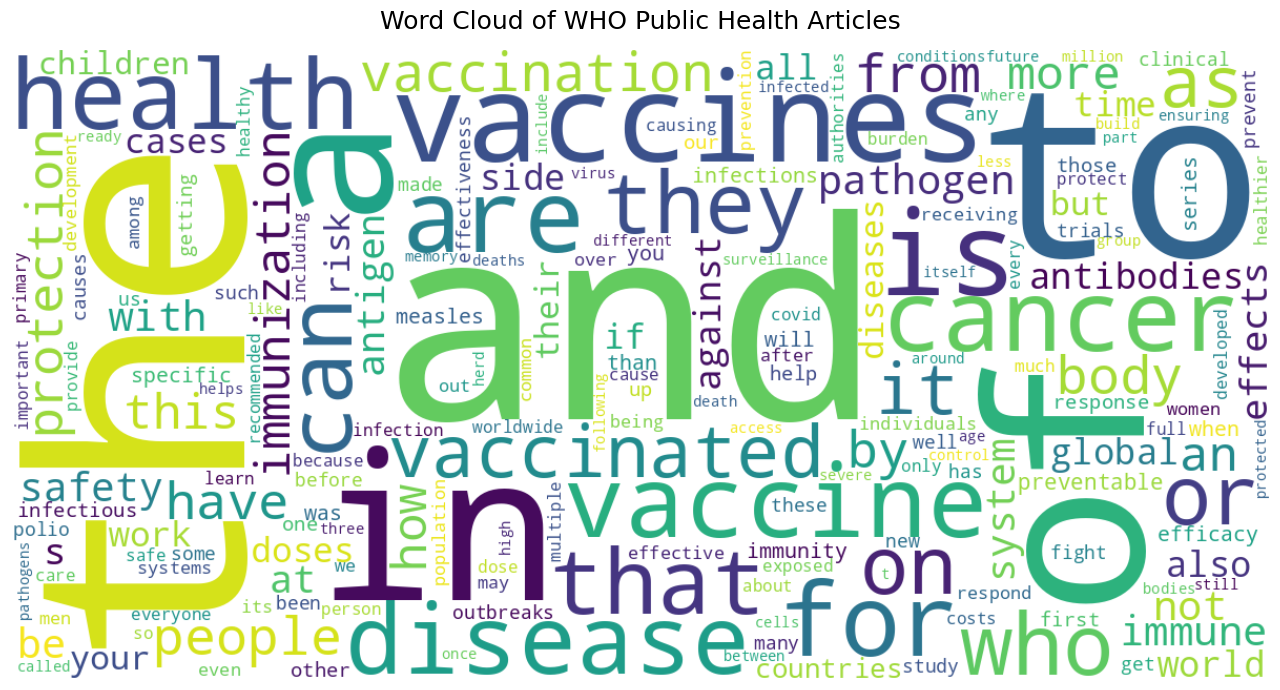

In [8]:
# Use the word frequencies already calculated in your notebook
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis",
    max_words=200,
    prefer_horizontal=0.9,
    collocations=False
).generate_from_frequencies(fdist)

plt.figure(figsize=(15, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title(
    "Word Cloud of WHO Public Health Articles",
    fontsize=18,
    pad=15
)
plt.tight_layout()
plt.show()

#### Relative Frequencies of the 200 Most Common Words

This code creates a line graph showing the relative frequencies of the 200 most common words, ranked from highest to lowest frequency. The graph helps visualize how word usage is distributed and whether a small number of words dominate the corpus.

The graph shows a sharp decline in relative frequency, indicating that a few words, such as “the,” “and,” and “to,” appear much more often than others. The curve gradually flattens as word rank increases, meaning that less common words contribute a smaller proportion of the total word occurrences. This pattern is consistent with Zipf’s law, which describes how a small number of words dominate a text while many others occur less frequently.

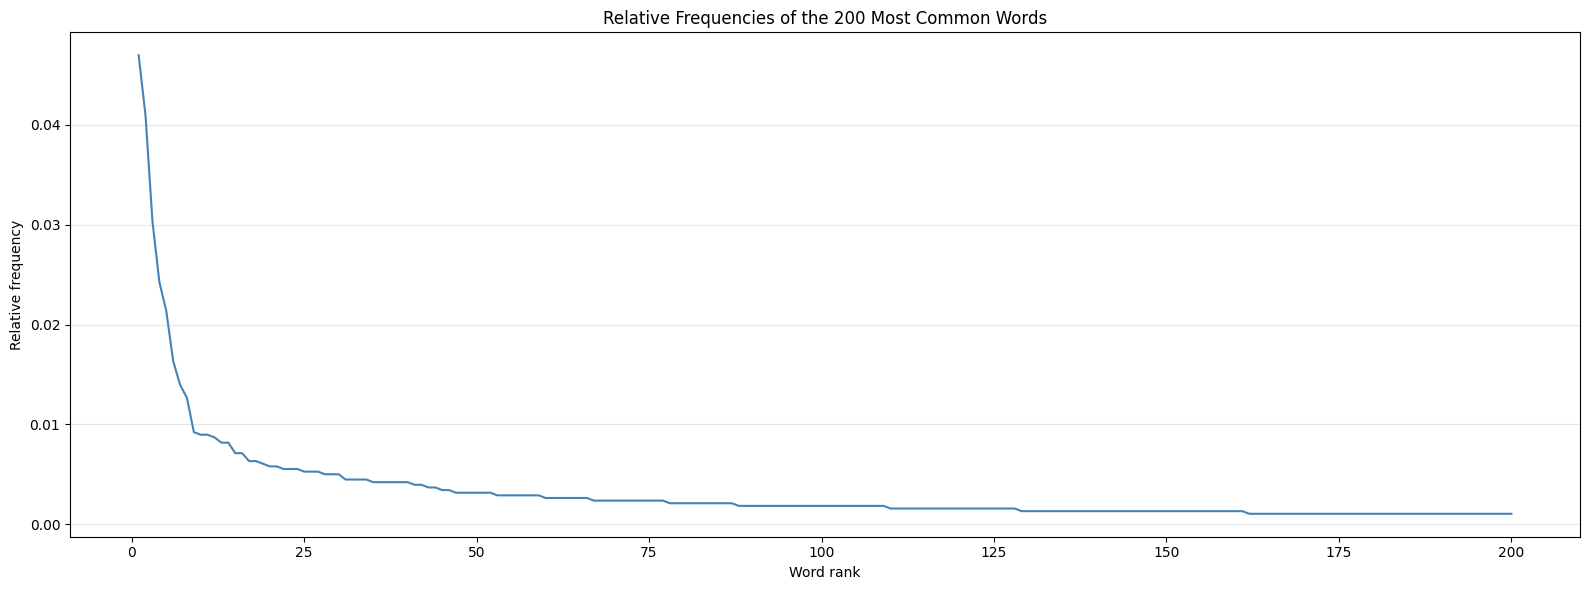

In [9]:
# Create a graph that shows the relative frequency of these 200 words.

plt.figure(figsize=(16, 6))

plt.plot(
    range(1, len(top_200) + 1),
    top_200["relative_frequency"],
    color="steelblue",
    linewidth=1.5
)

plt.title("Relative Frequencies of the 200 Most Common Words")
plt.xlabel("Word rank")
plt.ylabel("Relative frequency")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

#### Testing Zipf’s Law

This code creates a log-log graph of word frequency against word rank and calculates the slope of the distribution to compare it with the expected Zipf’s law slope of approximately −1. This helps determine whether the most common words occur much more frequently than less common words in the corpus, following a typical natural-language pattern.

The graph shows a downward trend, with the highest-ranked words appearing most frequently and many lower-ranked words occurring only a few times. The clusters near the bottom reflect words with similar, low frequencies. The estimated log-log slope is −0.883, which is relatively close to the −1 slope predicted by Zipf’s law. This suggests that the corpus generally follows a Zipf-like distribution, although it does not match the ideal relationship exactly. The slight difference may reflect the small size and specialized subject matter of the five WHO articles.

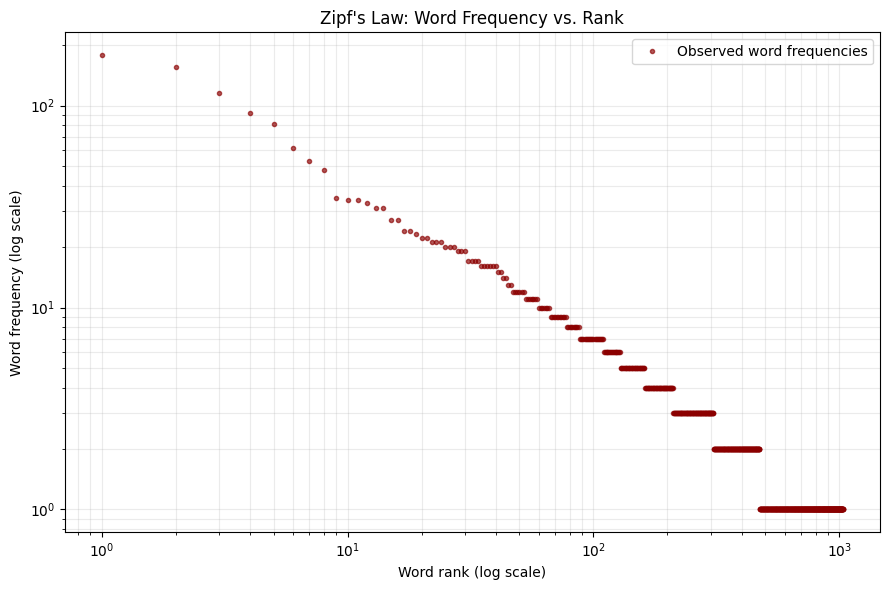

Estimated log-log slope: -0.883
Reference slope for idealized Zipf's law: approximately -1
Interpretation: The estimated slope is near -1, which is consistent with the simplest Zipf relationship. Inspect the graph as well before drawing a conclusion.


In [10]:
# Does the observed relative frequency of these words follow Zipf’s law? Explain.

ranks = np.arange(1, len(frequency_table) + 1)
counts = frequency_table["count"].to_numpy()

plt.figure(figsize=(9, 6))

plt.loglog(
    ranks,
    counts,
    marker=".",
    linestyle="none",
    color="darkred",
    alpha=0.65,
    label="Observed word frequencies"
)

plt.title("Zipf's Law: Word Frequency vs. Rank")
plt.xlabel("Word rank (log scale)")
plt.ylabel("Word frequency (log scale)")
plt.grid(True, which="both", alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

if len(counts) >= 2:
    slope, intercept = np.polyfit(
        np.log10(ranks),
        np.log10(counts),
        1
    )

    print(f"Estimated log-log slope: {slope:.3f}")
    print("Reference slope for idealized Zipf's law: approximately -1")

    if -1.2 <= slope <= -0.8:
        print(
            "Interpretation: The estimated slope is near -1, "
            "which is consistent with the simplest Zipf relationship. "
            "Inspect the graph as well before drawing a conclusion."
        )
    else:
        print(
            "Interpretation: The estimated slope differs from -1. "
            "The corpus may still show a Zipf-like pattern; examine "
            "the log-log graph and the limitations of this small corpus."
        )


#### Final Summary and Conclusion

This analysis examined five WHO public health articles containing 3,790 word tokens and 1,034 unique word types. The results showed that the 77 most frequent words accounted for approximately half of all word occurrences, demonstrating that a relatively small portion of the vocabulary dominates the corpus. The word-frequency graph showed a sharp decline followed by a gradual flattening, while the estimated log-log slope of −0.883 suggested a distribution reasonably consistent with Zipf’s law. These findings reflect the repeated use of common English words alongside specialized vocabulary related to vaccination, disease prevention, and public health. However, because the corpus contains only five articles from one organization, its word-frequency patterns may differ from those of larger, more diverse text collections. Overall, this project demonstrates how word-frequency analysis and visualization can reveal patterns in language and help us understand the vocabulary and communication priorities of public health organizations.

In [11]:
print(f"Articles analyzed: {len(corpus_df)}")
print(f"Total word tokens: {total_tokens:,}")
print(f"Unique word types: {unique_types:,}")
print(f"Word types accounting for at least half the corpus: {words_for_half}")
print(f"Number of words in top-200 table: {len(top_200)}")

if len(counts) >= 2:
    print(f"Estimated Zipf log-log slope: {slope:.3f}")

Articles analyzed: 5
Total word tokens: 3,790
Unique word types: 1,034
Word types accounting for at least half the corpus: 77
Number of words in top-200 table: 200
Estimated Zipf log-log slope: -0.883
